Check model performance on out-of-distribution samples by curating synthetic edge cases, analyzing model confidence levels, and assessing generalization ability beyond the training data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

df = pd.read_csv("heart_disease_train.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

for col in features + [target]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=features + [target]).copy()
X = df[features]
y = df[target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        class_weight="balanced"
    )
)

model.fit(X_train, y_train)

print("Model trained successfully.")

Model trained successfully.


In [2]:
normal_prob = model.predict_proba(X_test)[:, 1]
normal_pred = model.predict(X_test)

normal_results = {
    "Accuracy": accuracy_score(y_test, normal_pred),
    "F1 Score": f1_score(y_test, normal_pred, zero_division=0),
    "Mean Confidence": model.predict_proba(X_test).max(axis=1).mean()
}

print(pd.Series(normal_results).round(4))

Accuracy           0.7500
F1 Score           0.8333
Mean Confidence    0.7969
dtype: float64


In [3]:
rng = np.random.default_rng(42)

lower = X_train.min()
upper = X_train.max()
stds = X_train.std().replace(0, 1)

edge_cases = X_test.iloc[:min(100, len(X_test))].copy().reset_index(drop=True)

for col in features:
    edge_cases[col] = (
        edge_cases[col].to_numpy()
        + rng.choice([-1, 1], size=len(edge_cases)) * 2 * stds[col]
    )

print("Synthetic edge cases:", edge_cases.shape)
print(edge_cases.head())

Synthetic edge cases: (16, 5)
         age    trestbps        chol     thalach   oldpeak
0   1.275372  199.198331   -8.710252  244.274875  0.654829
1  88.724628   72.801669  503.710252  151.274875  2.454829
2  65.724628  221.198331  426.710252  179.274875  3.945171
3  13.275372   43.801669  193.289748   74.725125 -0.845171
4   9.275372  238.198331  662.710252    6.725125  0.554829


In [4]:
edge_probabilities = model.predict_proba(edge_cases)
edge_predictions = model.predict(edge_cases)

edge_results = pd.DataFrame({
    "Predicted Class": edge_predictions,
    "Probability Class 1": edge_probabilities[:, 1],
    "Maximum Confidence": edge_probabilities.max(axis=1)
})

print(edge_results.describe().round(4))

print(
    "High-confidence predictions (>= 0.90):",
    (edge_results["Maximum Confidence"] >= 0.90).sum()
)

print(
    "Low-confidence predictions (< 0.60):",
    (edge_results["Maximum Confidence"] < 0.60).sum()
)

       Predicted Class  Probability Class 1  Maximum Confidence
count           16.000              16.0000             16.0000
mean             0.625               0.5950              0.6800
std              0.500               0.1988              0.1208
min              0.000               0.2400              0.5600
25%              0.000               0.4300              0.5850
50%              1.000               0.6150              0.6450
75%              1.000               0.7125              0.7525
max              1.000               0.9900              0.9900
High-confidence predictions (>= 0.90): 1
Low-confidence predictions (< 0.60): 5


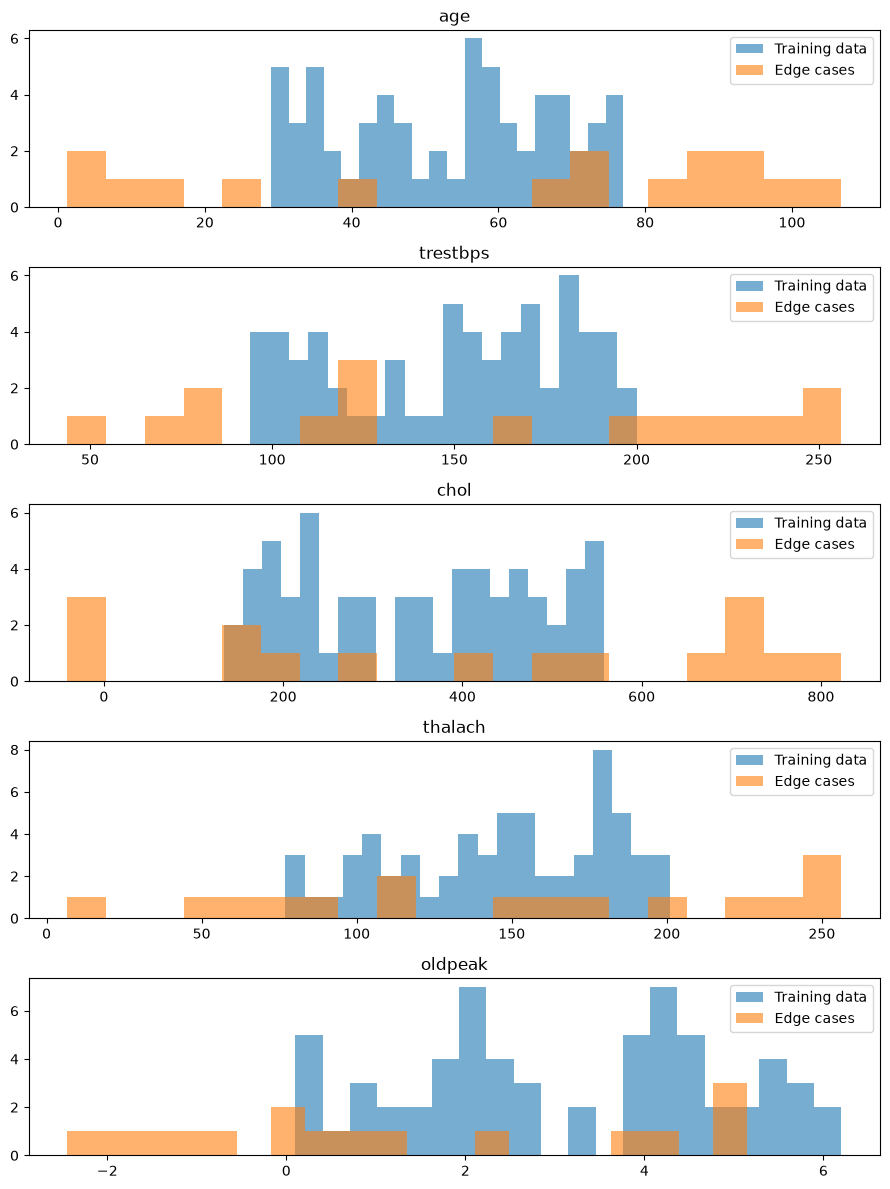

In [5]:
fig, axes = plt.subplots(len(features), 1, figsize=(9, 12))

for i, col in enumerate(features):
    axes[i].hist(
        X_train[col], bins=20, alpha=0.6, label="Training data"
    )
    axes[i].hist(
        edge_cases[col], bins=20, alpha=0.6, label="Edge cases"
    )
    axes[i].set_title(col)
    axes[i].legend()

plt.tight_layout()
plt.show()

             Dataset  Mean Confidence  Positive Prediction Rate
    Normal test data           0.7969                     0.750
Synthetic edge cases           0.6800                     0.625


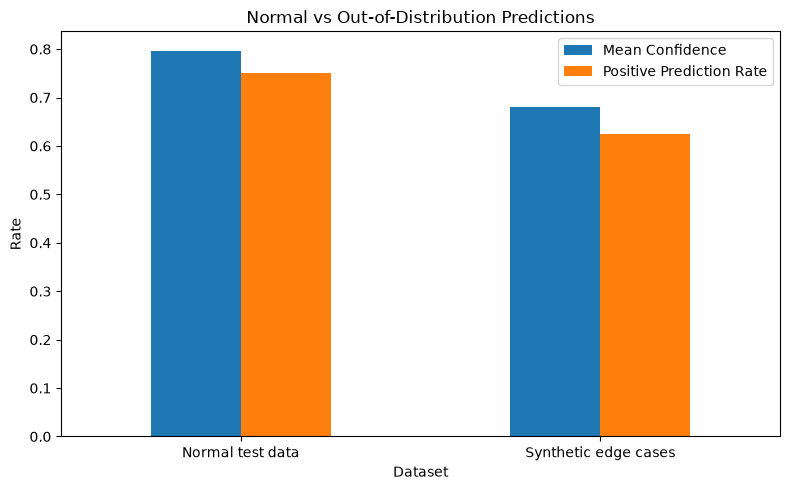

In [6]:
comparison = pd.DataFrame({
    "Dataset": ["Normal test data", "Synthetic edge cases"],
    "Mean Confidence": [
        model.predict_proba(X_test).max(axis=1).mean(),
        edge_probabilities.max(axis=1).mean()
    ],
    "Positive Prediction Rate": [
        normal_pred.mean(),
        edge_predictions.mean()
    ]
})

print(comparison.round(4).to_string(index=False))

comparison.set_index("Dataset").plot(
    kind="bar", figsize=(8, 5)
)

plt.title("Normal vs Out-of-Distribution Predictions")
plt.ylabel("Rate")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
outside_range = pd.DataFrame(index=edge_cases.index)

for col in features:
    outside_range[col] = (
        (edge_cases[col] < lower[col])
        | (edge_cases[col] > upper[col])
    )

edge_cases["Out-of-Range Features"] = outside_range.sum(axis=1)
edge_cases["Predicted Class"] = edge_predictions
edge_cases["Confidence"] = edge_probabilities.max(axis=1)

print(
    edge_cases[
        features + [
            "Out-of-Range Features",
            "Predicted Class",
            "Confidence"
        ]
    ].head(20).round(3).to_string(index=False)
)

    age  trestbps   chol  thalach  oldpeak  Out-of-Range Features  Predicted Class  Confidence
  1.275   199.198  -8.71  244.275    0.655                      3                0        0.63
 88.725    72.802 503.71  151.275    2.455                      2                1        0.86
 65.725   221.198 426.71  179.275    3.945                      1                1        0.99
 13.275    43.802 193.29   74.725   -0.845                      4                0        0.76
  9.275   238.198 662.71    6.725    0.555                      4                0        0.57
106.725   108.802 719.71  112.725    0.155                      2                1        0.75
 27.275   125.802 274.29  108.725    5.145                      1                0        0.57
 86.725   171.198 740.71   91.725   -0.945                      3                1        0.77
 38.275   256.198 -31.71  161.275   -1.945                      3                1        0.57
  4.275   204.198 822.71   67.725    1.055        